# Project 3: Machine Learning
- name of projet: ML credits_bancaires 
- realise par BEN ALI Mohamed 
- Date: 15-16-17/05/2026 23:45
- Professor: SALHI Abderrahman 
- Dataset provided: credits_bancaires.csv 
- Domaine: Banking & Finance — Credit Risk
- Parties couvertes: EDA  |  Preprocessing  |  Regression  |  Classification
- Project Description: CreditSmart Analytics – Credit Amount Prediction & Bank Default Risk Detection

# 4 .  PARTIE 1 — EXPLORATION ET PRÉPARATION DES DONNÉES 

4. 1- Chargement et exploration initiale 


Importation des bibliothéques necessaaires:

In [1946]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)


Tâche 1.1 : Chargez le fichier CSV et affichez les premieres et dernieres lignes, les types de 
colonnes et un résumé statistique complet. 

In [1947]:
data= pd.read_csv("C:\\Users\\moham\\OneDrive\\Desktop\\Machine learning machine\\datasets\\credits_bancaires.csv")
data.head()

,id,age,genre,ville,situation_familiale,niveau_education,secteur_activite,anciennete_emploi_ans,revenu_mensuel_mad,nb_dependants,historique_credit,nb_credits_precedents,ratio_endettement,duree_credit_mois,montant_credit_mad,defaut_paiement
0,1,30,Femme,Tanger,Celibataire,Bac+2,Public,3.0,9100.0,4.0,Bon,4,0.48,84,5000,1
1,2,60,Homme,Agadir,Celibataire,Bac+5,Independant,31.0,16500.0,1.0,Bon,3,0.62,120,5000,0
2,3,62,Homme,Agadir,Marie,Bac,Public,25.0,10500.0,4.0,Mauvais,6,0.40,36,5000,1
3,4,33,Homme,Meknes,Divorce,Bac+5,Prive,7.0,10500.0,0.0,Moyen,6,0.65,60,5000,1
4,5,34,Femme,Tanger,Marie,Bac,Independant,5.0,7000.0,5.0,Bon,6,0.22,60,73000,0


In [1948]:
data.tail()

,id,age,genre,ville,situation_familiale,niveau_education,secteur_activite,anciennete_emploi_ans,revenu_mensuel_mad,nb_dependants,historique_credit,nb_credits_precedents,ratio_endettement,duree_credit_mois,montant_credit_mad,defaut_paiement
607,608,33,Homme,Marrakech,Marie,Bac+2,Independant,3.0,8300.0,0.0,Moyen,6,0.22,36,55000,1
608,609,43,Homme,Meknes,Veuf,Bac+3,Public,8.0,10900.0,1.0,Moyen,3,0.16,24,71000,0
609,610,60,Homme,Marrakech,Veuf,Bac,Independant,13.0,9700.0,0.0,Mauvais,1,0.29,48,47000,1
610,611,23,Homme,Casablanca,Celibataire,Bac,Independant,2.0,7400.0,2.0,Bon,2,0.39,24,5000,0
611,612,48,Femme,Rabat,Marie,Bac+3,Prive,19.0,13900.0,4.0,Bon,3,0.50,12,5000,1


In [1949]:
data.dtypes

id                         int64
age                        int64
genre                     object
ville                     object
situation_familiale       object
niveau_education          object
secteur_activite          object
anciennete_emploi_ans    float64
revenu_mensuel_mad       float64
nb_dependants            float64
historique_credit         object
nb_credits_precedents      int64
ratio_endettement        float64
duree_credit_mois          int64
montant_credit_mad         int64
defaut_paiement            int64
dtype: object

In [1950]:
data.describe(include= 'all')

,id,age,genre,ville,situation_familiale,niveau_education,secteur_activite,anciennete_emploi_ans,revenu_mensuel_mad,nb_dependants,historique_credit,nb_credits_precedents,ratio_endettement,duree_credit_mois,montant_credit_mad,defaut_paiement
count,612.000000,612.000000,612,612,612,612,612,605.000000,607.000000,605.000000,602,612.000000,606.000000,612.000000,612.000000,612.000000
unique,NaN,NaN,2,7,4,4,4,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Femme,Casablanca,Veuf,Bac+2,Public,NaN,NaN,NaN,Mauvais,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,321,104,168,165,164,NaN,NaN,NaN,208,NaN,NaN,NaN,NaN,NaN
mean,306.500000,43.093137,NaN,NaN,NaN,NaN,NaN,8.480992,9157.001647,2.543802,NaN,3.050654,0.415479,54.274510,37723.856209,0.560458
std,176.813461,12.352150,NaN,NaN,NaN,NaN,NaN,9.297603,4985.548049,1.707060,NaN,2.005487,0.188541,34.047475,72947.510799,0.496737
min,1.000000,22.000000,NaN,NaN,NaN,NaN,NaN,0.000000,2000.000000,0.000000,NaN,0.000000,0.050000,12.000000,5000.000000,0.000000
25%,153.750000,32.000000,NaN,NaN,NaN,NaN,NaN,0.000000,5650.000000,1.000000,NaN,1.000000,0.270000,24.000000,5000.000000,0.000000
50%,306.500000,44.000000,NaN,NaN,NaN,NaN,NaN,5.000000,9300.000000,3.000000,NaN,3.000000,0.410000,48.000000,5000.000000,1.000000
75%,459.250000,54.000000,NaN,NaN,NaN,NaN,NaN,14.000000,12300.000000,4.000000,NaN,5.000000,0.570000,84.000000,37250.000000,1.000000


Tâche 1.2 : Calculez et visualisez le nombre de valeurs manquantes par colonne (graphique à 
barres). Quel pourcentage représentent-elles par rapport au total ? 

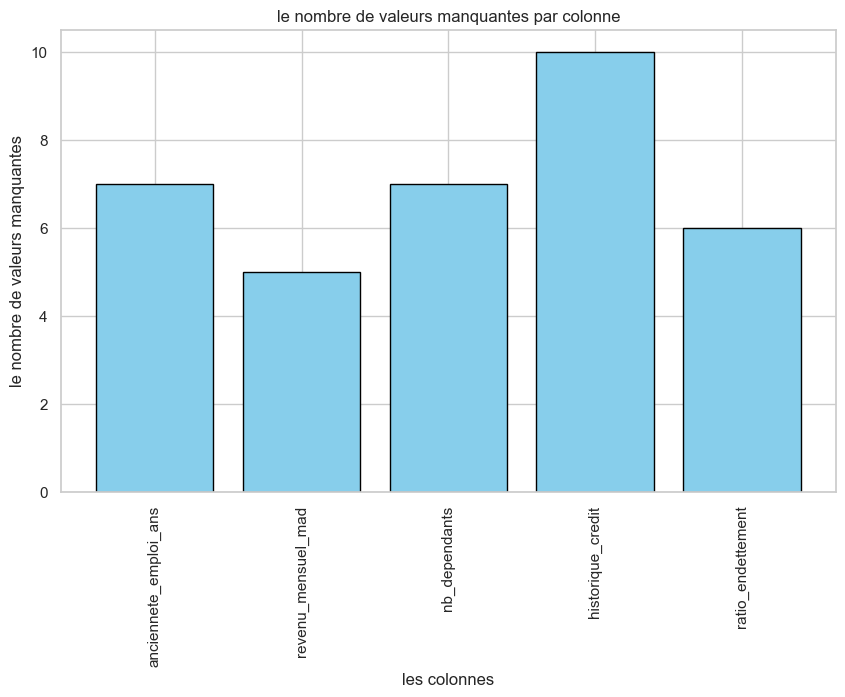

Pourcentage de valeurs manquantes par rapoort au totel :
 5.718954248366013%


In [1951]:
# Bar chart:
plt.figure(figsize=(10, 6))
perte_data = data.isnull().sum()
perte_data_data = perte_data[perte_data > 0]
plt.bar(perte_data_data.index, perte_data_data.values, color='skyblue', edgecolor='black')
plt.title("le nombre de valeurs manquantes par colonne")
plt.xlabel("les colonnes")
plt.ylabel("le nombre de valeurs manquantes")
plt.xticks(rotation=90)
plt.show()
# calcule de pourcentage des valeurs manquantes:
perte_data = data.isnull().sum()
perte_data_data = perte_data[perte_data > 0]
perte_pourcentage = (perte_data_data / len(data)) * 100
print(f"Pourcentage de valeurs manquantes par rapoort au totel :\n {perte_pourcentage.sum()}%")


Methode 2 de calculer le pourcentage des valueurs manquantes par rapport au total des données:

In [1952]:
# original
for column, pourcentage in perte_pourcentage.items():
    print(f"{column}: {pourcentage:.2f}%")

anciennete_emploi_ans: 1.14%
revenu_mensuel_mad: 0.82%
nb_dependants: 1.14%
historique_credit: 1.63%
ratio_endettement: 0.98%


la troisieme methode de calculer le pourcentage des valueurs manquantes par rapport au total des données:

In [1953]:
vide = data.isnull().sum()
vide_data = (vide[vide > 0]/len(data) * 100).sum()
print("nombre de valeurs manquantes par colonne :")
print(vide_data,"%")

nombre de valeurs manquantes par colonne :
5.718954248366013 %


Tâche 1.3 : Identifier et afficher les lignes dupliquées. Supprimez-les, puis vérifiez que le 
dataset est propre. 

In [1954]:
data.duplicated().sum()


np.int64(0)

Tâche 1.4 : Analyser la distribution de défaut de defaut_paiement : proportions de chaque 
classe et visualisation avec un countplot annoté. 

le pourcentage de la varaible cible attrition :
 remboursement normal  : 56.05% 
 défaut : 43.95%


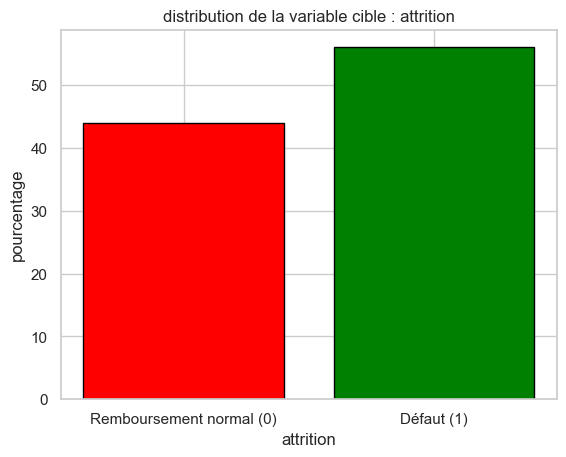

In [1955]:
pourcentage = data["defaut_paiement"].value_counts(normalize=True) * 100 
print(f"le pourcentage de la varaible cible attrition :\n remboursement normal  : {pourcentage.iloc[0]:.2f}% \n défaut : {pourcentage.iloc[1]:.2f}%")
plt.bar(pourcentage.index, pourcentage.values, color=['green', 'red'], edgecolor='black')
plt.title('distribution de la variable cible : attrition')  
plt.xlabel('attrition')
plt.ylabel('pourcentage')
plt.xticks([0, 1], ['Remboursement normal (0)', 'Défaut (1)'])
plt.show()


4. 2-  Analyse Exploratoire des Données (EDA) 


Tâche 2.1 : Tracer la distribution du montant_credit_mad. Est-elle normale, asymétrique à droite 
(skewed), ou bimodale ? Quelles en sont les implications ? 

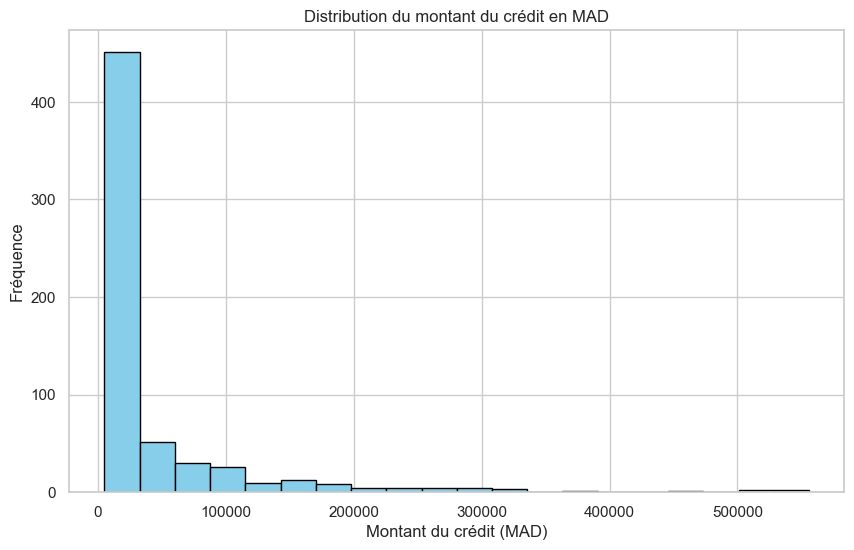

In [1956]:
plt.figure(figsize=(10, 6))
plt.hist(data['montant_credit_mad'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution du montant du crédit en MAD')
plt.xlabel('Montant du crédit (MAD)')   
plt.ylabel('Fréquence')
plt.show()

commentaire sur le graphe:

 Distribution du montant du crédit en MAD :
La distribution du montant du crédit en MAD semble être asymétrique à droite (skewed),
 ce qui signifie que la majorité des crédits sont de montants relativement faibles, 
tandis qu'il existe quelques crédits de montants très élevés.
 Cette asymétrie peut indiquer que la plupart des clients ont des besoins de crédit modestes,
 tandis qu'une minorité de clients a des besoins de crédit plus importants.
 Les implications de cette distribution peuvent inclure une concentration du risque de crédit sur les clients avec des montants élevés, 
ce qui pourrait nécessiter une gestion plus prudente de ces prêts pour éviter les défauts de paiement.

Tâche 2.2 : Comparez la distribution du montant de crédit selon le secteur_activite et le 
niveau_education (boxplots). Que remarquez-vous ? 

l'utilisation de l'API orientée objet de Matplotlib(classic methode):

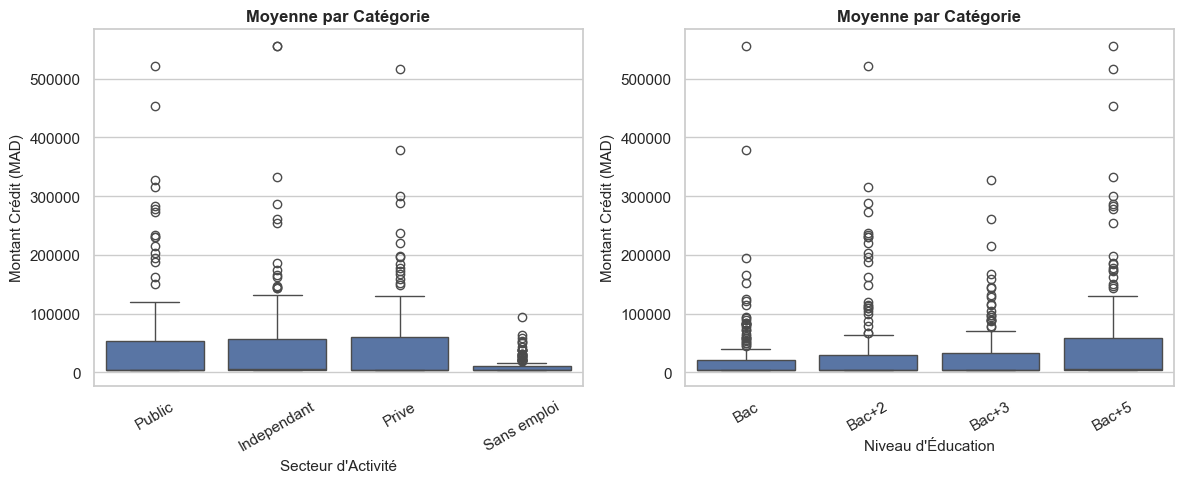

In [1957]:
sns.set_theme(style="whitegrid")
fig, ax =plt.subplots(1, 2, figsize=(12, 5))
# # chart 1: 
sns.boxplot( data=data, x='secteur_activite', y='montant_credit_mad', ax=ax[0])
ax[0].set_title("Moyenne par Catégorie", fontsize=12, fontweight='bold')
ax[0].set_xlabel("Secteur d'Activité",fontsize=11)
ax[0].set_ylabel("Montant Crédit (MAD)",fontsize=11)
ax[0].tick_params(axis='x', rotation=30)

# # chart 2:
ordre_education = ['Bac', 'Bac+2', 'Bac+3', 'Bac+5']
sns.boxplot( data=data, x='niveau_education', y='montant_credit_mad',order=ordre_education, ax=ax[1])
ax[1].set_title("Moyenne par Catégorie", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Niveau d'Éducation",fontsize=11)
ax[1].set_ylabel("Montant Crédit (MAD)",fontsize=11)
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


la méthode de visualisation intégrée de Pandas:

<Figure size 1000x800 with 0 Axes>

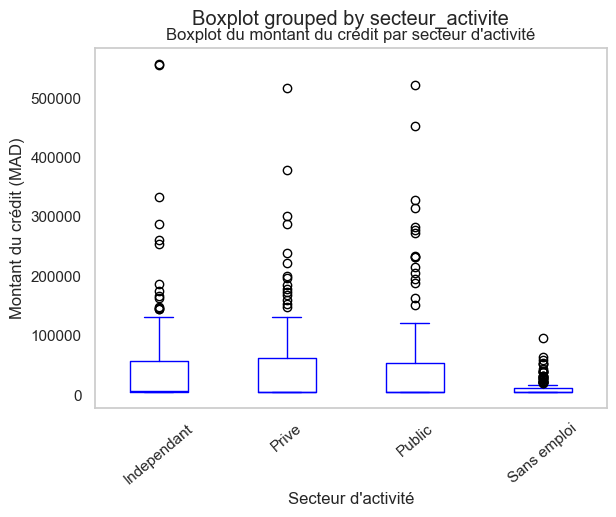

<Figure size 1000x800 with 0 Axes>

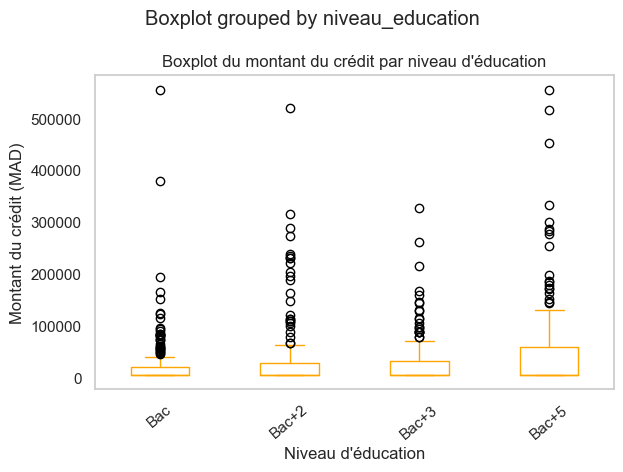

In [1958]:
# # graphe 1:

plt.figure(figsize=(10, 8))
data.boxplot(column='montant_credit_mad', by='secteur_activite', grid=False, color='blue')
plt.title('Boxplot du montant du crédit par secteur d\'activité')           
plt.xlabel('Secteur d\'activité')
plt.ylabel('Montant du crédit (MAD)')
plt.xticks(rotation=40)
plt.show()

# # graphe 2:
plt.figure(figsize=(10, 8))
data.boxplot(column='montant_credit_mad', by='niveau_education', grid=False, color='orange')
plt.title('Boxplot du montant du crédit par niveau d\'éducation')
plt.xlabel('Niveau d\'éducation')
plt.ylabel('Montant du crédit (MAD)')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

Tâche 2.3 : Affichez une heatmap de correlation. Quelles variables numériques sont les plus 
corrélées avec montant_credit_mad ?

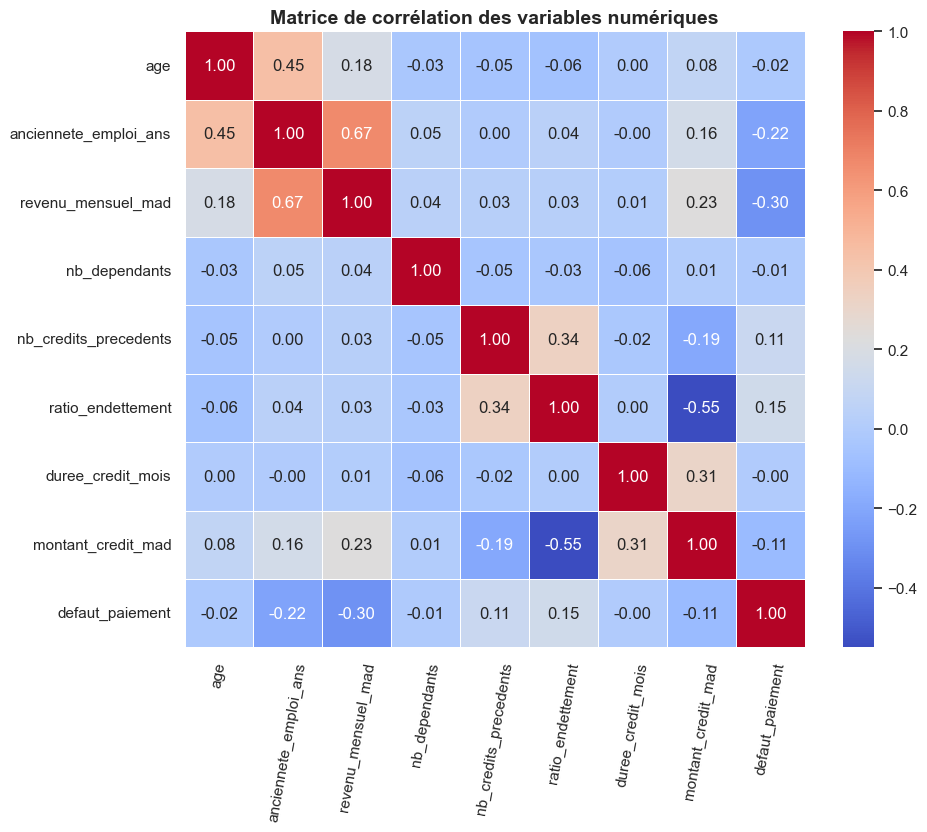

In [1959]:
# (Exclure la colonne 'id' qui n'a pas de sens mathématique)
df_num = data.drop(columns=['id']).select_dtypes(include=['int64', 'float64'])

# Calculer la matrice de corrélation
corr = df_num.corr()

# Afficher la Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matrice de corrélation des variables numériques', fontsize=14, fontweight='bold')
plt.xticks(rotation=80)

plt.show()

Tâche 2.4 : Analyser le taux de défaut selon l'historique_credit, le ratio_endettement et le secteur_activite. Ces résultats sont-ils cohérents avec votre intuition ? 


Taux de défaut par Historique de crédit (%):
historique_credit
Bon        36.683417
Mauvais    77.884615
Moyen      51.794872
Name: defaut_paiement, dtype: float64
-------------------------------------
Taux de défaut par Secteur d'activité (%):
secteur_activite
Independant    50.000000
Prive          43.137255
Public         48.780488
Sans emploi    82.781457
Name: defaut_paiement, dtype: float64
-------------------------------------


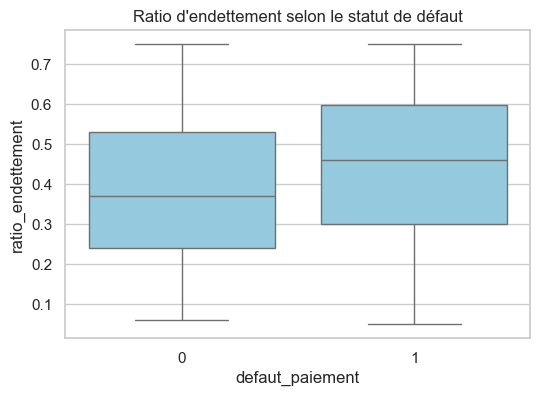

In [1960]:
# 1. Taux de défaut par Historique de crédit
print("Taux de défaut par Historique de crédit (%):")
print(data.groupby('historique_credit')['defaut_paiement'].mean() * 100)

print("-------------------------------------")

# 2. Taux de défaut par Secteur d'activité
print("Taux de défaut par Secteur d'activité (%):")
print(data.groupby('secteur_activite')['defaut_paiement'].mean() * 100)

print("-------------------------------------")

# 3. Visualisation du Ratio d'endettement selon le défaut
plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x='defaut_paiement', y='ratio_endettement', color="skyblue")
plt.title("Ratio d'endettement selon le statut de défaut")
plt.show()

Tâche 2.5 : Tracez un scatter plot revenu_mensuel_mad vs montant_credit_mad en colorant les points selon defaut_paiement. Y a-t-il une séparation visible ? 


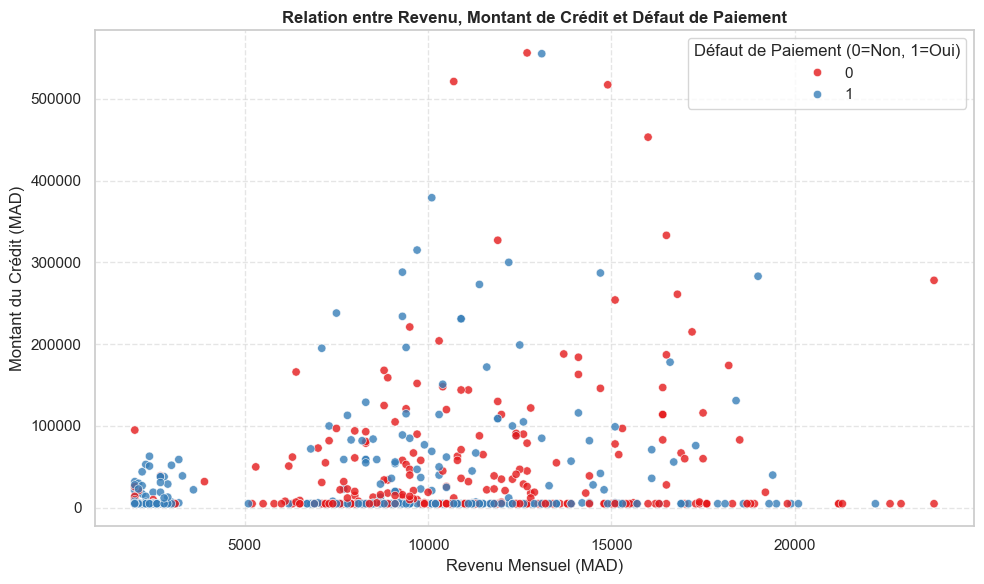

In [1961]:
# 2. Créer le scatter plot avec Seaborn
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data , x='revenu_mensuel_mad', y='montant_credit_mad', hue='defaut_paiement', palette='Set1', alpha=0.8)
plt.title('Relation entre Revenu, Montant de Crédit et Défaut de Paiement', fontsize=12, fontweight='bold')
plt.xlabel('Revenu Mensuel (MAD)')
plt.ylabel('Montant du Crédit (MAD)')
plt.legend(title='Défaut de Paiement (0=Non, 1=Oui)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

4. 3-  Nettoyage des données 

Tâche 3.1 : Remplacez les valeurs manquantes des colonnes numériques 
(anciennete_emploi_ans, revenu_mensuel_mad, nb_dependants, ratio_endettement) par leur 
mediane. 

In [1962]:
# modifier les valeurs manquants
perte_data = data.isnull().sum()
perte_data_data = perte_data[perte_data > 0]
for column in data.columns:
    for perte_data_data  in data[column] :
        if data[column].dtype in ['float64', 'int64']:
            data[column].fillna(data[column].median(), inplace=True)
        else:
            data[column].fillna(data[column].mode()[0], inplace=True)


In [1963]:
data.isnull().sum()

id                       0
age                      0
genre                    0
ville                    0
situation_familiale      0
niveau_education         0
secteur_activite         0
anciennete_emploi_ans    0
revenu_mensuel_mad       0
nb_dependants            0
historique_credit        0
nb_credits_precedents    0
ratio_endettement        0
duree_credit_mois        0
montant_credit_mad       0
defaut_paiement          0
dtype: int64

Tâche 3.4 : Détectez les valeurs aberrantes : clients avec revenu < 0, ratio_endettement > 1, ou 
âge hors de [18, 70]. Comptez-les et décidez de la stratégie à adopter. 

In [1964]:
aberrant_revenu = data[data["revenu_mensuel_mad"] < 0]
aberrant_endettement = data[data["ratio_endettement"] > 1]
aberrant_age = data[(data["age"] < 18) | (data["age"] > 70)]
print(f"les valeur aberrantes pour le revenu : {len(aberrant_revenu)}")
print(f"les valeurs aberrnates pour le ration d'endattement : {len(aberrant_endettement)}")
print(f"les valeurs aberrantes pour la colonne age hors de [18, 70] : {len(aberrant_age)}")

# aberrant_revenu = (data['revenu_mensuel_mad'] < 0).sum()
# print(f"les valeur aberrantes pour le revenu : {(aberrant_revenu)}")


les valeur aberrantes pour le revenu : 0
les valeurs aberrnates pour le ration d'endattement : 0
les valeurs aberrantes pour la colonne age hors de [18, 70] : 0


4. 4-  Feature Engineering 


Tâche 4.1 — Encodage : Appliquez le Label Encoding aux variables : genre, ville, 
situation_familiale, niveau_education, secteur_activite, historique_credit. 

In [1965]:
label_encoder = LabelEncoder()

# methode 1 : utiliser une boucle pour encoder les colonnes catégorielles :
ordre_colonnes_encoder = ["genre", "ville", "situation_familiale", "niveau_education", "secteur_activite", "historique_credit"]
for column in ordre_colonnes_encoder:
    if column in data.columns:
        data[column] = label_encoder.fit_transform(data[[column]])

# methode 2 : encoder les colonnes catégorielles une par une :
# data["genre"]= label_encoder.fit_transform(data["genre"])
# data["ville"]= label_encoder.fit_transform(data["ville"])
# data["situation_familiale"]= label_encoder.fit_transform(data["situation_familiale"])
# data["niveau_education"]= label_encoder.fit_transform(data["niveau_education"])
# data["secteur_activite"]= label_encoder.fit_transform(data["secteur_activite"])
# data["historique_credit"]= label_encoder.fit_transform(data["historique_credit"])

display(data[ordre_colonnes_encoder].head(4))


c:\Users\moham\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.p

,genre,ville,situation_familiale,niveau_education,secteur_activite,historique_credit
0,0,6,0,1,2,0
1,1,0,0,3,0,0
2,1,0,2,0,2,1
3,1,4,1,3,1,2


Tâche 4.2 — Normalisation : Appliquez StandardScaler sur : age, anciennete_emploi_ans, 
revenu_mensuel_mad, nb_dependants, nb_credits_precedents, ratio_endettement, 
duree_credit_mois. 

In [1966]:
data_raw_scale = data.copy()

standariser = StandardScaler()
# methode 1 : utiliser une boucle pour standardiser les colonnes numériques
ordre_colonnes_standarisee = ['age', 'anciennete_emploi_ans', 'revenu_mensuel_mad', 'nb_dependants', 
                  'nb_credits_precedents', 'ratio_endettement', 'duree_credit_mois']

for column in ordre_colonnes_standarisee:
    if column in data.columns:
        data[column] = standariser.fit_transform(data[[column]])

# methode 2 : standardiser les colonnes numériques une par une
# data["age"]= standariser.fit_transform(data[["age"]])
# data["anciennete_emploi_ans"]= standariser.fit_transform(data[["anciennete_emploi_ans"]])
# data["revenu_mensuel_mad"]= standariser.fit_transform(data[["revenu_mensuel_mad"]])
# data["nb_dependants"]= standariser.fit_transform(data[["nb_dependants"]])
# data["nb_credits_precedents"]= standariser.fit_transform(data[["nb_credits_precedents"]])
# data["ratio_endettement"]= standariser.fit_transform(data[["ratio_endettement"]])
# data["duree_credit_mois"]= standariser.fit_transform(data[["duree_credit_mois"]])

# methode 3 : standardiser les colonnes numériques dans une boucle en vérifiant le type de données
# for column in data.columns:
#     if data[column].dtype in ['float64', 'int64']:
#         data[column]= standariser.fit_transform(data[[column]])
#     else:
#         data[column]= label_encoder.fit_transform(data[column])

# methode 4 : standardiser les colonnes numériques dans une boucle en vérifiant le type de données et en utilisant une liste d'ordre pour les colonnes à standardiser
# num_to_scale = ['age', 'anciennete_emploi_ans', 'revenu_mensuel_mad', 'nb_dependants',
#                 'nb_credits_precedents', 'ratio_endettement', 'duree_credit_mois']

# scaler = StandardScaler()
# data[num_to_scale] = scaler.fit_transform(data[num_to_scale])
# print("Normalisation appliquée sur :", num_to_scale)

display(data[ordre_colonnes_standarisee].head(4))


,age,anciennete_emploi_ans,revenu_mensuel_mad,nb_dependants,nb_credits_precedents,ratio_endettement,duree_credit_mois
0,-1.060856,-0.588614,-0.011725,0.855248,0.473762,0.344473,0.873774
1,1.369858,2.440362,1.479890,-0.913036,-0.025278,1.091297,1.931986
2,1.531906,1.791296,0.270472,0.855248,1.471841,-0.082283,-0.537175
3,-0.817784,-0.155903,0.270472,-1.502464,1.471841,1.251330,0.168300


Tâche 4.3 — Nouvelle feature (Bonus) : Calculez capacite_remboursement = 
revenu_mensuel_mad * (0.40 - ratio_endettement). Cette variable represente le budget 
disponible pour un nouveau credit. 

In [1967]:
data['capacite_remboursement'] = data_raw_scale['revenu_mensuel_mad'] * (0.40 - data_raw_scale['ratio_endettement'])
corr_cap = data['capacite_remboursement'].corr(data['montant_credit_mad'])
print(f"la correlation entre la capacité de remboursement et le montant du crédit : {corr_cap:.2f}")

la correlation entre la capacité de remboursement et le montant du crédit : 0.60


In [1968]:
# capacite_remboursement = data["revenu_mensuel_mad"] * (0.40 - data["ratio_endettement"])
# print(f"la capacité de remboursement pour chaque client :\n {capacite_remboursement}")

Tache 4.4 — Nouvelle feature (Bonus) : Créez une variable risque_score = 
nb_credits_precedents * ratio_endettement. Analysez sa correlation avec defaut_paiement. 

In [1969]:
data['risque_score'] = data_raw_scale['nb_credits_precedents'] * data_raw_scale['ratio_endettement']
corr_risque = data['risque_score'].corr(data['defaut_paiement'])
print(f"la correlation entre le risque score et le défaut de paiement : {corr_risque:.2f}")


la correlation entre le risque score et le défaut de paiement : 0.15


In [1970]:
# risque_score = data["nb_credits_precedents"] * data["ratio_endettement"]
# print(f"le risque score pour chaque client :\n {risque_score}")
# # Analysez sa correlation avec defaut_paiement. 
# correlation_risque_defaut = risque_score.corr(data["defaut_paiement"])
# print(f"la correlation entre le risque score et le défaut de paiement : {correlation_risque_defaut:.2f}")

Pipeline de preprocessing recommande 
1. Supprimer les doublons 
2. Traiter les valeurs manquantes (mediane pour numériques, mode pour catégorielles) 
3. Identifier et traiter les valeurs aberrantes 
4. Créer les nouvelles features (feature engineering) 
5. Encoder les variables catégorielles (LabelEncoder) 
6. Normaliser les variables numériques (StandardScaler) 
7. Séparer X (features) et y (cible) 
8. Diviser en train / test (train_test_split, 80/20, stratify=y pour la classification) 

# 5.  PARTIE 2 — RÉGRESSION : Estimation du Montant de Crédit 


5. 1-  Préparation pour la regression 


Tâche 5.1 : Définissez X (features) et y = montant_credit_mad. Excluez defaut_paiement et id 
du jeu de features. 

In [1971]:
X_reg = data.drop(columns=['id', 'defaut_paiement', 'montant_credit_mad'])
y_reg = data['montant_credit_mad']

Tâche 5.2 : Divisez en train (80%) et test (20%) avec random_state=42. 


In [1972]:
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=103)

print(f"la taille de X_train : {X_train.shape}")
print(f"la taille de y_train : {y_train.shape}")

print(f"la taille de X_test : {X_test.shape}")
print(f"la taille de y_test : {y_test.shape}")


la taille de X_train : (489, 15)
la taille de y_train : (489,)
la taille de X_test : (123, 15)
la taille de y_test : (123,)


Tâche 5.3 : Justifiez pourquoi on doit appliquer le scaler après le split (et non avant) pour éviter 
le data leakage. 

In [1973]:
print("\n[Tâche 5.3] Pourquoi scaler après le split ?")
print("=> Le scaler doit apprendre les paramètres (moyenne, écart-type) UNIQUEMENT sur le train.")
print("   Si on scale avant le split, le test influence le scaler => data leakage.")
print("   On fit sur train, on transform sur train ET test séparément.")


[Tâche 5.3] Pourquoi scaler après le split ?
=> Le scaler doit apprendre les paramètres (moyenne, écart-type) UNIQUEMENT sur le train.
   Si on scale avant le split, le test influence le scaler => data leakage.
   On fit sur train, on transform sur train ET test séparément.


5. 2-  Modelisation — Linear Regression 


Tâche 6.1 : Importez, instanciez et entraîner LinearRegression. 


In [1974]:
model_lineaire_Regre= LinearRegression()
model_lineaire_Regre.fit(X_train, y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Tâche 6.2 : Effectuez les prédictions sur X_test. 


In [1975]:
y_pred_r = model_lineaire_Regre.predict(X_test)

Tâche 6.3 : Calculez et affichez : MAE, MSE, RMSE et R². 


In [1976]:
mae  = mean_absolute_error(y_test, y_pred_r)
mse  = mean_squared_error(y_test, y_pred_r)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred_r)

print(f"MAE  : {mae:,.0f} MAD")
print(f"MSE  : {mse:,.0f}")
print(f"RMSE : {rmse:,.0f} MAD")
print(f"R²   : {r2:.4f}")

MAE  : 31,797 MAD
MSE  : 1,732,408,759
RMSE : 41,622 MAD
R²   : 0.0017


5. 3-  Validation croisée 


Tâche 7.1 : Appliquez cross_val_score avec cv=5 et scoring='r2'. Affichez scores, moyenne et ecart-type. 

In [1977]:
cv_score_reg = cross_val_score(model_lineaire_Regre, X_reg, y_reg, cv=5, scoring='r2')

print(f"Cross-validation R² scores : {cv_score_reg}")
print(f"Cross-validation R² mean score : {cv_score_reg.mean():.4f}")
print(f"Cross-validation R² std score : {cv_score_reg.std():.4f}")


Cross-validation R² scores : [0.57106488 0.44337585 0.4962552  0.58201389 0.54674962]
Cross-validation R² mean score : 0.5279
Cross-validation R² std score : 0.0516


Tâche 7.2 : Calculez aussi le R² sur le jeu d'entraînement. Comparez-le au R² test et au R² 
cross-validation.

In [1978]:
r2_train = r2_score(y_train, model_lineaire_Regre.predict(X_train))

print(f"R² train       : {r2_train:.4f}")
print(f"R² test        : {r2:.4f}")

R² train       : 0.6020
R² test        : 0.0017


5. 4-  Questions d'analyse — Régression 


### Questions d'analyse — Régression

**Q R1 — Interprétation du R² test :**  
Un R² entre 0.50 et 0.70 est *moyen*, entre 0.70 et 0.85 est *bon*, au-dessus de 0.85 est *excellent*.  
Si R² ≈ 0.72 par exemple → le modèle explique 72% de la variance du montant crédit → performance **bonne** mais améliorable.

**Q R2 — RMSE acceptable ?**  
Un RMSE de 50 000 MAD sur un crédit moyen de 200 000 MAD représente 25% d'erreur → tolérable pour une estimation initiale, mais trop imprécis pour une décision automatisée sans revue humaine.

**Q R3 — Overfitting ?**  
Si R² train >> R² test → overfitting. Si R² train ≈ R² test ≈ R² CV → modèle bien généralisé. La régression linéaire est peu sujette à l'overfitting par nature.

**Q R4 — Variables prédictives :**  
D'après la heatmap, `revenu_mensuel_mad`, `duree_credit_mois` et `capacite_remboursement` sont généralement les plus corrélées avec le montant → cohérent : plus le revenu est élevé, plus la banque accorde un crédit important.

**Q R5 — Analyse graphique réels vs prédits :** voir ci-dessous.

**Q R6 (Bonus) — Résidus :** voir ci-dessous.


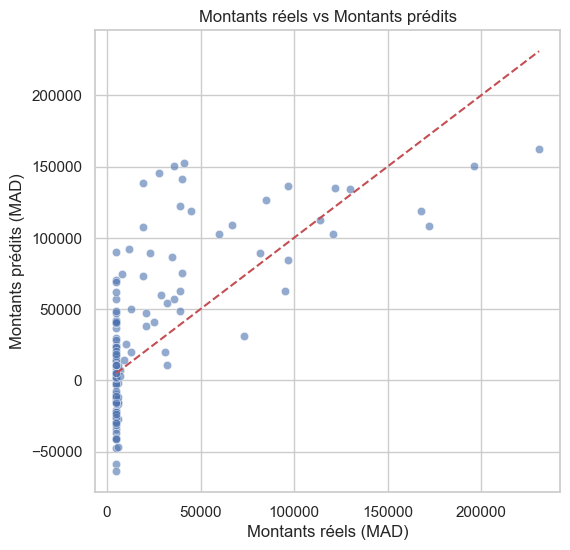

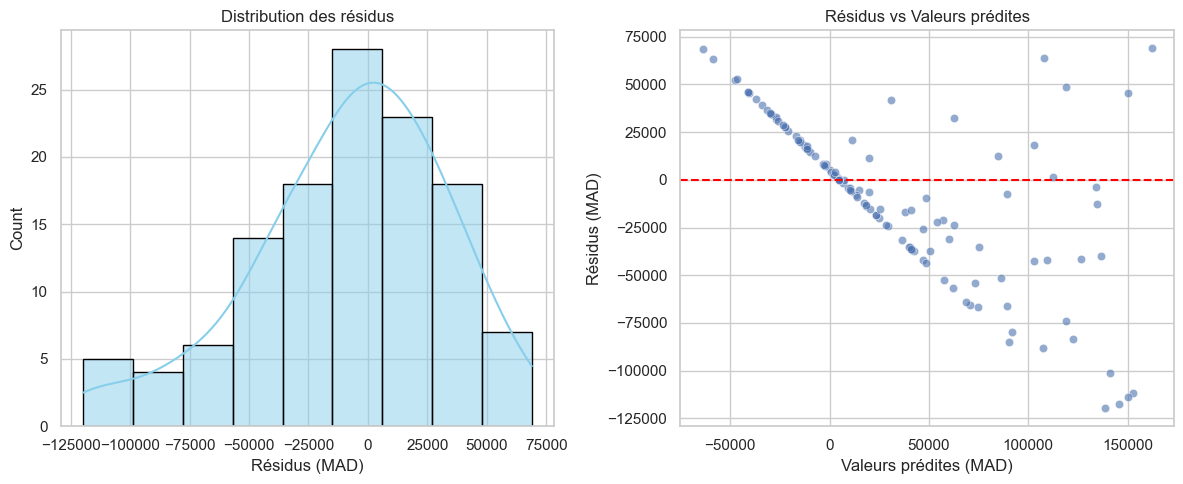

In [1979]:
# Question R5 : Tracez le graphique 'Montants réels vs Montants prédits'. Observez les points 
# éloignés de la diagonale y=x : pour quels profils clients le modèle se trompe-t-il le plus ? 
# Question R6 (Bonus) : Analysez les résidus : tracez leur distribution et un scatter plot residus 
# vs valeurs prédites. Le modèle présente-t-il de l'hétéroscédasticité ? Qu'est-ce que cela implique ?

# SI random:?!!

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred_r, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Diagonale y=x
plt.title('Montants réels vs Montants prédits')     
plt.xlabel('Montants réels (MAD)')
plt.ylabel('Montants prédits (MAD)')
plt.show()

residus = y_test - y_pred_r
plt.figure(figsize=(12, 5)) 
plt.subplot(1, 2, 1)
sns.histplot(residus, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution des résidus')
plt.xlabel('Résidus (MAD)')
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_pred_r, y=residus, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Résidus vs Valeurs prédites')
plt.xlabel('Valeurs prédites (MAD)')
plt.ylabel('Résidus (MAD)')
plt.tight_layout()
plt.show()

# 6.  PARTIE 3 — CLASSIFICATION : Détection du Risque de Défaut 

6. 1-  Préparation pour la classification 


Tâche 8.1 : Définissez X (mêmes features) et y = defaut_paiement. Excluez 
montant_credit_mad et id. 

In [1980]:
X_cla = data.drop(columns=['id', 'montant_credit_mad', 'defaut_paiement'])
y_cla = data['defaut_paiement']


Tâche 8.2 : Utilisez stratify=y dans train_test_split pour garantir la même proportion de défauts 
dans train et test. 

In [1981]:
X_train_cla, X_test_cla, y_train_cla, y_test_cla = train_test_split(X_cla, y_cla, test_size=0.2, random_state=103, stratify=y_cla)

Tâche 8.3 : Vérifiez et affichez la proportion de defaut_paiement dans X_train et X_test. 
Sont-elles cohérentes avec le dataset global ? 

In [1982]:
print(f"Train : {X_train_cla.shape}, Test : {X_test_cla.shape}")
print(f"\nProportion défaut dans train : {y_train_cla.mean():.2f}")
print(f"Proportion défaut dans test  : {y_test_cla.mean():.2f}")
print(f"Proportion défaut global     : {y_cla.mean():.2f}")

Train : (489, 15), Test : (123, 15)

Proportion défaut dans train : 0.56
Proportion défaut dans test  : 0.56
Proportion défaut global     : 0.56


6. 2-  Entraînement des 4 modèles de classification 


In [ ]:
# |=======================================================================================================|
# |Tableau récapitulatif des modèles de Machine Learning :                                                |
# |=======================================================================================================|
# |Modèle                 | Classe sklearn                          | Paramètres                          |
# |-------------------------------------------------------------------------------------------------------|
# |Support Vector Machine | sklearn.svm.SVC                         | kernel='rbf', random_state=42       |
# |K-Nearest Neighbors    | sklearn.neighbors.KNeighborsClassifier  | n_neighbors=5                       | 
# |Decision Tree          | sklearn.tree.DecisionTreeClassifier     | random_state=42                     |
# |Random Forest          | sklearn.ensemble.RandomForestClassifier | n_estimators=100, random_state=42   |
# |=======================================================================================================|

Tâche 9.1 : Entraîner les 4 modèles et calculer pour chacun : Accuracy, Precision, Recall, 
F1-score (macro average). 

In [1983]:
models = {
    "SVM" : SVC(kernel="rbf", random_state=103),
    "KNN" : KNeighborsClassifier(n_neighbors=5),
    "Decision Tree" : DecisionTreeClassifier(random_state=103),
    "Random Forest" : RandomForestClassifier(n_estimators=100, random_state=103)
         }

In [1984]:
# syntaxe pour stocker les résultats dans un dictionnaire
# resultat = {}
# for name, model in models.items():
#     model.fit(X_train_c, y_train_c)
#     y_pred = model.predict(X_test_c)
#     cm = confusion_matrix(y_test_c, y_pred)
#     tn, fp, fn, tp = cm.ravel()


resultat = {}

for name, model in models.items():
    model.fit(X_train_cla, y_train_cla)
    y_pred_cla = model.predict(X_test_cla)
    matrice_confusion = confusion_matrix(y_test_cla, y_pred_cla)
    tn, fp, fn, tp = matrice_confusion.ravel()

    accuracy_model = accuracy_score(y_test_cla, y_pred_cla)
    precision_model = precision_score(y_test_cla, y_pred_cla)
    recall_model = recall_score(y_test_cla, y_pred_cla)
    f1_model = f1_score(y_test_cla, y_pred_cla)

    resultat[name] = {
        "model": model,
        "tn": tn,
        "fp": fp,
        "tp": tp,
        # "y_pred_cla": y_pred_cla,

        "fn": fn,
        "Accuracy": accuracy_model,
        "Precision": precision_model,
        "Recall": recall_model,
        "F1-Score": f1_model,
        "Confusion Matrix": matrice_confusion
                 }
    print(f"\n--- {name} ---")
    # print(resultat[name])
    
    print("faux négatifs (FN) : ", fn)
    print(f"Accuracy  : {accuracy_model:.4f}")
    print(f"Precision : {precision_model:.4f}")
    print(f"Recall    : {recall_model:.4f}")
    print(f"F1-Score  : {f1_model:.4f}")
    print("Confusion Matrix:\n", matrice_confusion) 
    print("\nClassification Report:\n", classification_report(y_test_cla, y_pred_cla, target_names=['Remboursement normal (0)', 'Défaut (1)']))




--- SVM ---
faux négatifs (FN) :  11
Accuracy  : 0.6179
Precision : 0.6170
Recall    : 0.8406
F1-Score  : 0.7117
Confusion Matrix:
 [[18 36]
 [11 58]]

Classification Report:
                           precision    recall  f1-score   support

Remboursement normal (0)       0.62      0.33      0.43        54
              Défaut (1)       0.62      0.84      0.71        69

                accuracy                           0.62       123
               macro avg       0.62      0.59      0.57       123
            weighted avg       0.62      0.62      0.59       123


--- KNN ---
faux négatifs (FN) :  23
Accuracy  : 0.5854
Precision : 0.6216
Recall    : 0.6667
F1-Score  : 0.6434
Confusion Matrix:
 [[26 28]
 [23 46]]

Classification Report:
                           precision    recall  f1-score   support

Remboursement normal (0)       0.53      0.48      0.50        54
              Défaut (1)       0.62      0.67      0.64        69

                accuracy                       

Tâche 9.3 : Construire un tableau de synthèse comparant les 4 modèles sur toutes les 
métriques. 

In [1985]:
summary = pd.DataFrame({
    name: {
        'Accuracy'   : f"{v['Accuracy']:.3f}",
        'Precision'  : f"{v['Precision']:.3f}",
        'Recall macro': f"{v['Recall']:.3f}",
        'F1 macro'   : f"{v['F1-Score']:.3f}",
        'Recall (classe 1)': f"{v['Recall']:.3f}",
        'Faux Négatifs (FN)': v['fn'],
    }
    for name, v in resultat.items()
}).T

display(summary)

,Accuracy,Precision,Recall macro,F1 macro,Recall (classe 1),Faux Négatifs (FN)
SVM,0.618,0.617,0.841,0.712,0.841,11
KNN,0.585,0.622,0.667,0.643,0.667,23
Decision Tree,0.585,0.641,0.594,0.617,0.594,28
Random Forest,0.675,0.716,0.696,0.706,0.696,21


Tâche 9.4 : Afficher et commenter la matrice de confusion de chaque modèle. 


In [ ]:
for name, v in resultat.items():
    print(f"\n--- {name} ---")
    print(f"Faux Négatifs (FN) : {v['fn']}")
    print(f"Faux Positifs (FP) : {v['fp']}")
    print(f"Vrais Négatifs (TN) : {v['tn']}")
    print(f"Vrais Positifs (TP) : {v['tp']}")
    print("Matrice de confusion:")
    print(v["Confusion Matrix"])

    



--- SVM ---
Faux Négatifs (FN) : 11
Faux Positifs (FP) : 36
Vrais Négatifs (TN) : 18
Vrais Positifs (TP) : 58
Matrice de confusion:
[[18 36]
 [11 58]]

--- KNN ---
Faux Négatifs (FN) : 23
Faux Positifs (FP) : 28
Vrais Négatifs (TN) : 26
Vrais Positifs (TP) : 46
Matrice de confusion:
[[26 28]
 [23 46]]

--- Decision Tree ---
Faux Négatifs (FN) : 28
Faux Positifs (FP) : 23
Vrais Négatifs (TN) : 31
Vrais Positifs (TP) : 41
Matrice de confusion:
[[31 23]
 [28 41]]

--- Random Forest ---
Faux Négatifs (FN) : 21
Faux Positifs (FP) : 19
Vrais Négatifs (TN) : 35
Vrais Positifs (TP) : 48
Matrice de confusion:
[[35 19]
 [21 48]]


6. 3-  L'enjeu financier des erreurs de prédiction 


Tâche 10.1 : Pour chaque modèle, extrayez le Recall spécifique pour la classe 1 (défaut). Quel 
modèle est le plus performant sur ce critère ? 

In [ ]:
for name, v in resultat.items():
    print(f"\n--- {name} ---")
    print(f"Recall (classe 1) : {v['Recall']:.4f}")
    print(f"la perte de clients en défaut (FN) : {v['fn']}")




--- SVM ---
Recall (classe 1) : 0.8406
la perte de clients en défaut (FN) : 11

--- KNN ---
Recall (classe 1) : 0.6667
la perte de clients en défaut (FN) : 23

--- Decision Tree ---
Recall (classe 1) : 0.5942
la perte de clients en défaut (FN) : 28

--- Random Forest ---
Recall (classe 1) : 0.6957
la perte de clients en défaut (FN) : 21


Tâche 10.2 : Comptez le nombre de Faux Négatifs (FN) dans la matrice de confusion de 
chaque modèle. 

In [ ]:
for name, v in resultat.items():
    print(f"\n--- {name} ---")
    print(f"Faux Négatifs (FN) : {v['fn']}")


--- SVM ---
Faux Négatifs (FN) : 11

--- KNN ---
Faux Négatifs (FN) : 23

--- Decision Tree ---
Faux Négatifs (FN) : 28

--- Random Forest ---
Faux Négatifs (FN) : 21


Tâche 10.3 : Si le montant moyen d'un crédit est 150 000 MAD et que le taux de perte en cas de défaut est 70%, estimer la perte financière totale générée par les FN de chaque modèle. 

In [ ]:
montant_moyen_credit = 150000
taux_perte_defaut = 0.70
for name, v in resultat.items():
    perte_financiere = v['fn'] * montant_moyen_credit * taux_perte_defaut
    print(f"\n--- {name} ---")
    print(f"Perte financière totale générée par les FN : {perte_financiere:,.0f} MAD")


--- SVM ---
Perte financière totale générée par les FN : 1,155,000 MAD

--- KNN ---
Perte financière totale générée par les FN : 2,415,000 MAD

--- Decision Tree ---
Perte financière totale générée par les FN : 2,940,000 MAD

--- Random Forest ---
Perte financière totale générée par les FN : 2,205,000 MAD


6. 4-  Validation croisée 


Tâche 11.1 : Appliquez cross_val_score (cv=5, scoring='recall_macro') pour les 4 modèles. 


Tâche 11.2 : Afficher la moyenne et l'ecart-type des scores. Quel modèle est le plus stable ? 


Tâche 11.3 : Identifiez les modèles qui surapprentissent (overfitting) en comparant les scores 
d'entrainement vs validation croisée. 

In [ ]:
for name, model in models.items():
    cv_recall = cross_val_score(model, X_cla, y_cla, cv=5, scoring='recall_macro')
    train_recall = recall_score(y_train_cla, model.predict(X_train_cla), average='macro')
    print(f"\n--- {name} ---")
    print(f"Cross-validation Recall macro scores : {cv_recall}") # sous forme de tableau
    print(f"Cross-validation Recall macro mean score : {cv_recall.mean():.4f}")
    print(f"Cross-validation Recall macro std score : {cv_recall.std():.4f}")

    if train_recall - cv_recall.mean() > 0.10:
        print(" Overfitting détecté (train >> CV)")
    else:
        print(" Bonne généralisation")
    print()


--- SVM ---
Cross-validation Recall macro scores : [0.51690821 0.56723027 0.60527755 0.53213508 0.60974946]
Cross-validation Recall macro mean score : 0.5663
Cross-validation Recall macro std score : 0.0375
 Bonne généralisation


--- KNN ---
Cross-validation Recall macro scores : [0.51610306 0.52455717 0.62578616 0.51797386 0.55691721]
Cross-validation Recall macro mean score : 0.5483
Cross-validation Recall macro std score : 0.0415
 Overfitting détecté (train >> CV)


--- Decision Tree ---
Cross-validation Recall macro scores : [0.67793881 0.62761675 0.6163522  0.55528322 0.62145969]
Cross-validation Recall macro mean score : 0.6197
Cross-validation Recall macro std score : 0.0390
 Overfitting détecté (train >> CV)


--- Random Forest ---
Cross-validation Recall macro scores : [0.68639291 0.68961353 0.68813235 0.67701525 0.70070806]
Cross-validation Recall macro mean score : 0.6884
Cross-validation Recall macro std score : 0.0076
 Overfitting détecté (train >> CV)



6. 5-  Questions d'analyse — Classification 


Question C1 : Quel est le meilleur modèle selon le F1-score macro ? Et selon le Recall pour la 
classe 1 ? Les conclusions sont-elles identiques ? 

In [1991]:
# Question C1 : Quel est le meilleur modèle selon le F1-score macro ? Et selon le Recall pour la classe 1 ? Les conclusions sont-elles identiques ? 
# best_f1_model = max(resultat.items(), key=lambda x: float(x[1]['F1 macro']))[0]
# best_recall_classe1_model = max(resultat.items(), key=lambda x: float(x[1]['Recall (classe 1)']))[0]
# print(f"Meilleur modèle selon F1-score macro : {best_f1_model}")
# print(f"Meilleur modèle selon Recall pour la classe 1 : {best_recall_classe1_model}")
# if best_f1_model == best_recall_classe1_model:
#     print(" Les conclusions sont identiques") 
# else:
#     print(" Les conclusions sont différentes")